In [1]:
import sys, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
sys.path.append('../src')

import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

from models.dreamrec import DreamRec
from data import build_dataloaders

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

In [2]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
CKPT_DIR   = '../checkpoints/dreamrec_baseline'
DATA_DIR   = '../data/ATG'
N_ITEMS    = 11924
PADDING    = 11924
N_SAMPLES  = 1000   # сколько примеров из val усреднять
BATCH_SIZE = 1024
SEED       = 42    # seed для воспроизводимости

# w_cfg при сэмплировании (None = брать из чекпойнта)
# Примеры: 0.0 = чистое conditional (без guidance)
#          1.0 = умеренный guidance
#          2.0 = сильный guidance (дефолт DreamRec)
W_CFG_OVERRIDE = 2

import random, numpy as np
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [3]:
# Загружаем чекпойнт и модель
from pathlib import Path
ckpt_path = Path(CKPT_DIR) / 'best.pt'
if not ckpt_path.exists():
    ckpt_path = Path(CKPT_DIR) / 'latest.pt'
print(f'Checkpoint: {ckpt_path}')

ckpt = torch.load(ckpt_path, map_location=device)
sd   = ckpt['model_state']
print(f'epoch={ckpt.get("epoch")}, metrics={ckpt.get("metrics")}')

# Архитектура из state_dict
d_model    = sd['item_embedding.weight'].shape[1]
T          = sd['betas'].shape[0]
cfg        = ckpt.get('model_cfg', {})
w_cfg_ckpt = cfg.get('w_cfg', 0.0)
w_cfg      = W_CFG_OVERRIDE if W_CFG_OVERRIDE is not None else w_cfg_ckpt
print(f'd_model={d_model}, T={T}, w_cfg={w_cfg}  (ckpt w_cfg={w_cfg_ckpt})')

model = DreamRec(n_items=N_ITEMS, padding_idx=PADDING,
                 d_model=d_model, T=T, w_cfg=w_cfg).to(device)
model.load_state_dict(sd)

# EMA weights
ema_shadow = ckpt.get('ema_shadow', {})
if ema_shadow:
    for name, param in model.named_parameters():
        if name in ema_shadow:
            param.data.copy_(ema_shadow[name].to(device))
    print('EMA weights loaded')

model.eval()
print('Model ready')

Checkpoint: ..\checkpoints\dreamrec_baseline\best.pt
epoch=190, metrics={'HR@10': 0.009273570030927658, 'NDCG@10': 0.004486697260290384, 'HR@20': 0.014940752647817135, 'NDCG@20': 0.005841305945068598}
d_model=64, T=1000, w_cfg=2  (ckpt w_cfg=2.0)
EMA weights loaded
Model ready


In [4]:
# Загружаем все сплиты
import pandas as pd
loaders = build_dataloaders(data_dir=DATA_DIR, batch_size=BATCH_SIZE,
                             num_workers=0, splits=('train', 'val', 'test'))
print(f'Train: {len(loaders["train"].dataset):,} sequences')
print(f'Val:   {len(loaders["val"].dataset):,} sequences')
print(f'Test:  {len(loaders["test"].dataset):,} sequences')

Train: 15,529 sequences
Val:   1,941 sequences
Test:  1,942 sequences


In [5]:

# ════════════════════════════════════════════════════════════
# Вспомогательные функции
# ════════════════════════════════════════════════════════════

@torch.no_grad()
def sample_with_tracking(model, h, target_emb):
    B  = h.shape[0]
    W  = model.item_embedding.weight[:model.n_items]
    rand_idx   = torch.randint(0, model.n_items, (B,), device=h.device)
    random_emb = W[rand_idx]
    x = torch.randn_like(h)

    tracking = {k: [] for k in [
        'step', 'l2_target', 'l2_random', 'dot_target', 'dot_random', 'cos_target', 'cos_random'
    ]}

    def record(step, x_cur):
        tracking['step'].append(step)
        for name, ref in [('target', target_emb), ('random', random_emb)]:
            tracking[f'l2_{name}'].append((x_cur - ref).pow(2).sum(-1).sqrt().mean().item())
            tracking[f'dot_{name}'].append((x_cur * ref).sum(-1).mean().item())
            tracking[f'cos_{name}'].append(F.cosine_similarity(x_cur, ref, dim=-1).mean().item())

    record(0, x)
    for i, t_idx in enumerate(reversed(range(model.T))):
        x = model.p_sample(x, h, t_idx)
        record(i + 1, x)
    return tracking


def hit_ratio(rankings, targets, k):
    return (rankings[:, :k] == targets.unsqueeze(-1)).any(dim=-1).float().mean().item()


def ndcg(rankings, targets, k):
    top_k   = rankings[:, :k]
    matches = (top_k == targets.unsqueeze(-1))
    rank    = matches.float().argmax(dim=-1)
    hit     = matches.any(dim=-1)
    return (1.0 / torch.log2(rank.float() + 2.0) * hit.float()).mean().item()


@torch.no_grad()
def analyze_split(model, loader, split_name, n_samples=N_SAMPLES, seed=SEED):
    """Строит trajectory plot и таблицу метрик для одного сплита."""
    W = model.item_embedding.weight[:model.n_items].detach()

    # ── Трекинг траектории (N_SAMPLES примеров) ──────────────────
    torch.manual_seed(seed)
    track_keys = ['l2_target', 'l2_random', 'dot_target', 'dot_random', 'cos_target', 'cos_random']
    acc = {k: None for k in track_keys}
    n_track, n_track_batches = 0, 0

    for batch in loader:
        if n_track >= n_samples:
            break
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target'].to(device)
        h          = model.encode_history(history, mask, apply_cfg_dropout=False)
        target_emb = model.item_embedding(target)
        tr = sample_with_tracking(model, h, target_emb)
        for k in track_keys:
            arr = np.array(tr[k])
            acc[k] = arr if acc[k] is None else acc[k] + arr
        n_track += history.shape[0]
        n_track_batches += 1

    for k in track_keys:
        acc[k] /= n_track_batches
    steps = np.array(tr['step'])

    # ── График ───────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for ax, (title, prefix, higher_is_closer) in zip(axes, [
        ('L2 Distance',       'l2',  False),
        ('Dot Product',       'dot', True),
        ('Cosine Similarity', 'cos', True),
    ]):
        ax.plot(steps, acc[f'{prefix}_target'], color='tomato',    lw=2, label='Target item')
        ax.plot(steps, acc[f'{prefix}_random'], color='steelblue', lw=2, label='Random item', ls='--')
        ax.set_title(title, fontsize=12)
        ax.set_xlabel('Sampling step (0 = noise, T = final)')
        ax.set_ylabel(f'{"↓" if not higher_is_closer else "↑"} closer')
        ax.legend(fontsize=9)
        ax.set_xlim(0, len(steps) - 1)

    plt.suptitle(
        f'{split_name.upper()} — DreamRec sampling trajectory  (T={model.T}, {n_track} samples)',
        fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

    # ── Метрики (весь сплит) ──────────────────────────────────────
    torch.manual_seed(seed)
    r_dot, r_cos, r_l2, r_rnd = [], [], [], []
    all_targets = []
    total_loss, n_loss = 0.0, 0

    for batch in loader:
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target'].to(device)
        B       = history.shape[0]

        z_0      = model.item_embedding(target)
        t        = torch.randint(0, model.T, (B,), device=device)
        eps      = torch.randn_like(z_0)
        x_t      = model.sqrt_alphas_cumprod[t].unsqueeze(1) * z_0 + \
                   model.sqrt_one_minus_alphas_cumprod[t].unsqueeze(1) * eps
        h        = model.encode_history(history, mask, apply_cfg_dropout=False)
        total_loss += F.mse_loss(model.forward(x_t, h, t), z_0).item()
        n_loss += 1

        oracle = model.sample(h)

        r_dot.append((oracle @ W.T).topk(20, dim=-1).indices.cpu())

        r_cos.append(
            (F.normalize(oracle, dim=-1) @ F.normalize(W, dim=-1).T).topk(20, dim=-1).indices.cpu()
        )

        l2_sq = (oracle.pow(2).sum(-1, keepdim=True) - 2.0 * oracle @ W.T
                 + W.pow(2).sum(-1).unsqueeze(0))
        r_l2.append(l2_sq.topk(20, dim=-1, largest=False).indices.cpu())

        r_rnd.append(torch.stack([torch.randperm(model.n_items)[:20] for _ in range(B)]))
        all_targets.append(target.cpu())

    targets_all = torch.cat(all_targets, dim=0)
    loss_val    = total_loss / n_loss

    rows = []
    for name, rlist in [('Dot Product', r_dot), ('Cosine Sim', r_cos),
                        ('L2 Distance', r_l2),  ('Random',     r_rnd)]:
        r = torch.cat(rlist, dim=0)
        rows.append({'Retrieval': name,
                     'HR@10':   round(hit_ratio(r, targets_all, 10), 4),
                     'NDCG@10': round(ndcg(r, targets_all, 10), 4),
                     'HR@20':   round(hit_ratio(r, targets_all, 20), 4),
                     'NDCG@20': round(ndcg(r, targets_all, 20), 4)})

    df = pd.DataFrame(rows).set_index('Retrieval')
    print(f'{split_name.capitalize()} Loss: {loss_val:.4f}\n')
    print(df.to_string())
    print()
    return df, loss_val


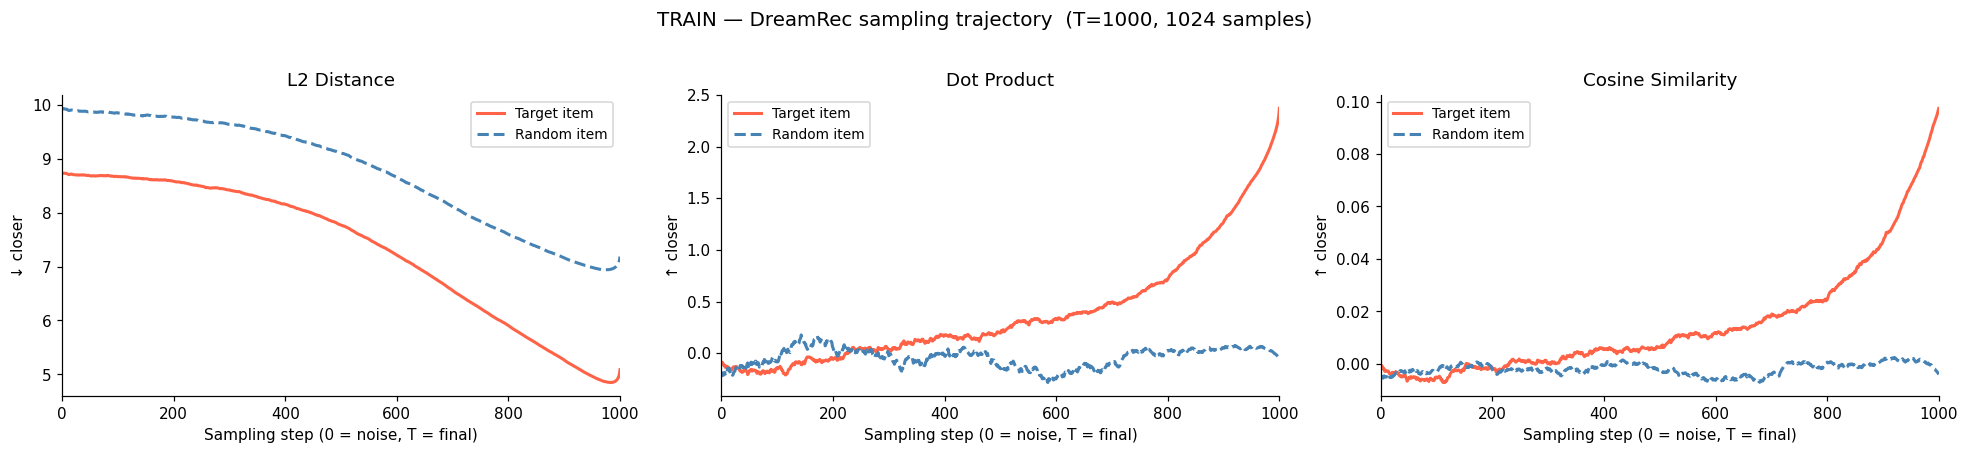

Train Loss: 0.1579

              HR@10  NDCG@10   HR@20  NDCG@20
Retrieval                                    
Dot Product  0.0033   0.0018  0.0046   0.0022
Cosine Sim   0.0257   0.0167  0.0355   0.0192
L2 Distance  0.0376   0.0221  0.0552   0.0265
Random       0.0012   0.0006  0.0018   0.0007



In [6]:
model.eval()
train_df, train_loss = analyze_split(model, loaders['train'], 'train')

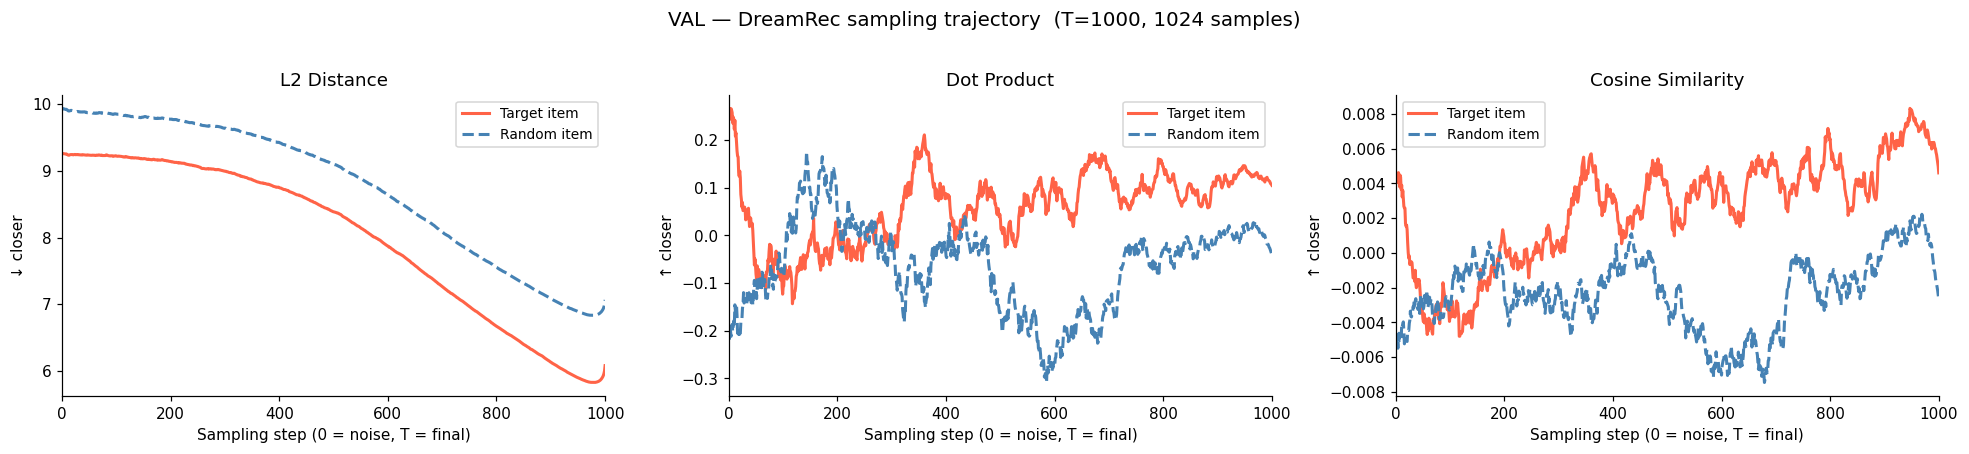

Val Loss: 0.2809

              HR@10  NDCG@10   HR@20  NDCG@20
Retrieval                                    
Dot Product  0.0010   0.0003  0.0015   0.0005
Cosine Sim   0.0026   0.0019  0.0026   0.0019
L2 Distance  0.0093   0.0045  0.0149   0.0059
Random       0.0005   0.0002  0.0021   0.0006



In [7]:
val_df, val_loss = analyze_split(model, loaders['val'], 'val')

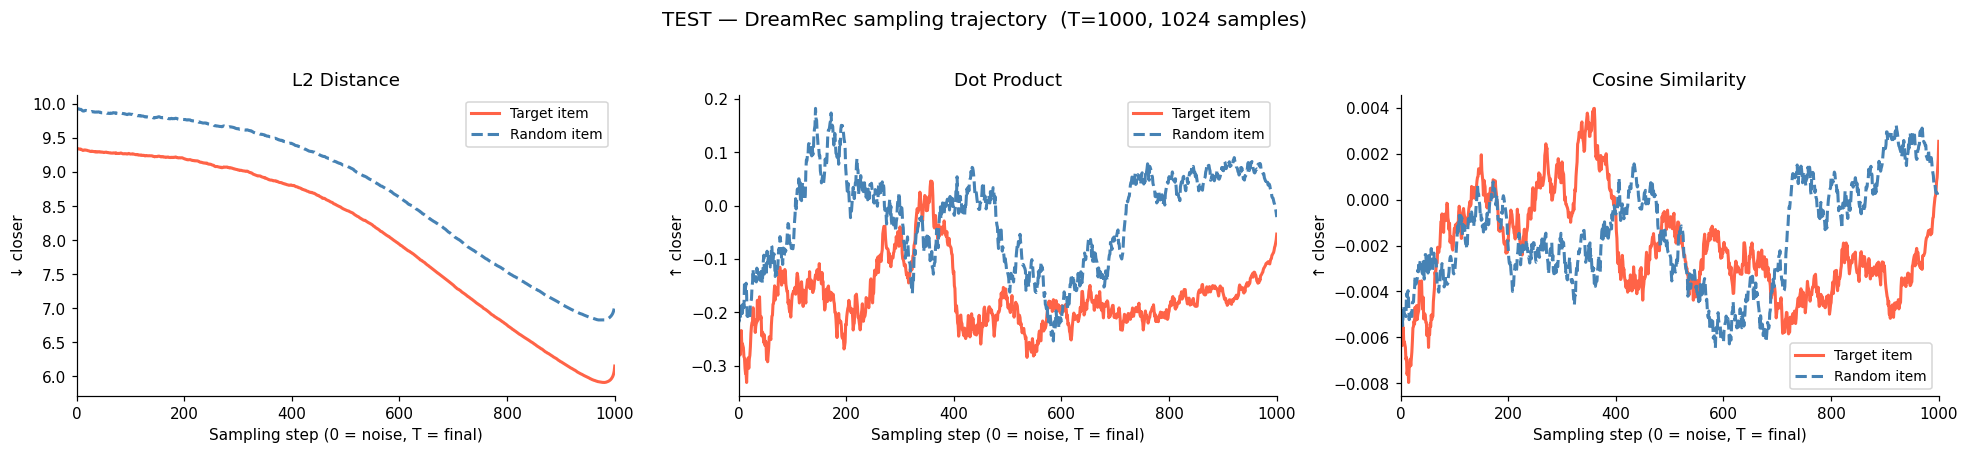

Test Loss: 0.2859

              HR@10  NDCG@10   HR@20  NDCG@20
Retrieval                                    
Dot Product  0.0021   0.0006  0.0026   0.0008
Cosine Sim   0.0031   0.0023  0.0036   0.0024
L2 Distance  0.0098   0.0058  0.0180   0.0078
Random       0.0010   0.0004  0.0021   0.0007



In [8]:
test_df, test_loss = analyze_split(model, loaders['test'], 'test')